## 1.Import Necessary Libraries

In [2]:
import pandas as pd
from matplotlib import pyplot as pyt
import seaborn as sb
import warnings
warnings.filterwarnings(action="ignore")

from sklearn.linear_model import LinearRegression

In [4]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2.Import DataSet

In [3]:
car_data=pd.read_csv("Cars.csv")
car_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 3.Data Understanding

#### 3.1 Perform Initial Investigation on the data

In [4]:
car_data.shape

(81, 5)

In [5]:
car_data.isna().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [6]:
car_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [7]:
car_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


## Now Let check for the Assumptions

## Test1 :linearity Test

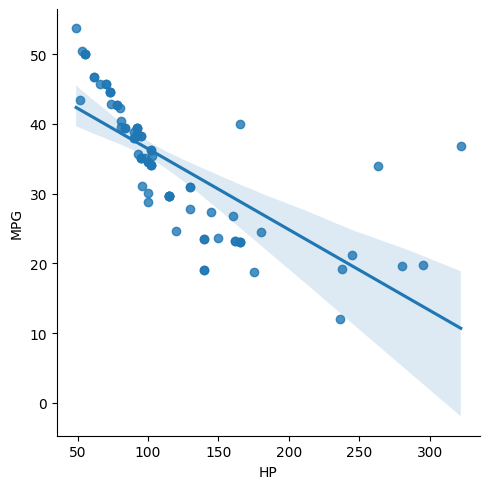

In [19]:
sb.lmplot(data=car_data,x="HP",y="MPG")   ## is not linear line as little bit scatter

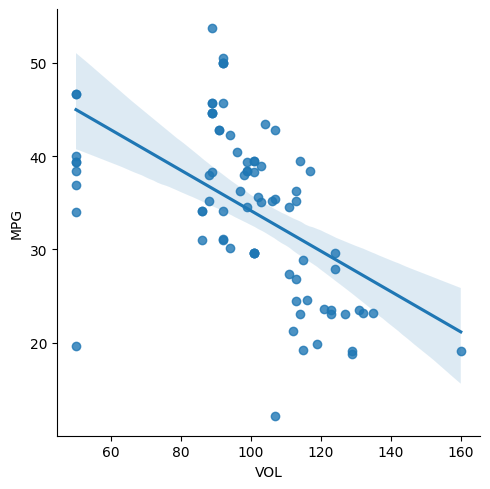

In [20]:
sb.lmplot(data=car_data,x="VOL",y="MPG")

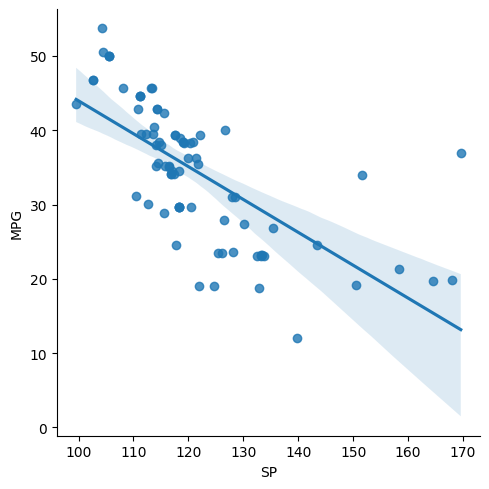

In [22]:
sb.lmplot(data=car_data,x="SP",y="MPG")

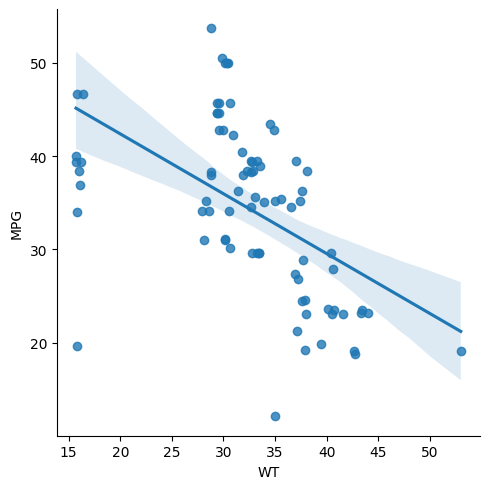

In [23]:
sb.lmplot(data=car_data,x="WT",y="MPG")

#### Test 1 Linearity Failed



## Test 2 Normal Linearity

<Axes: ylabel='Density'>

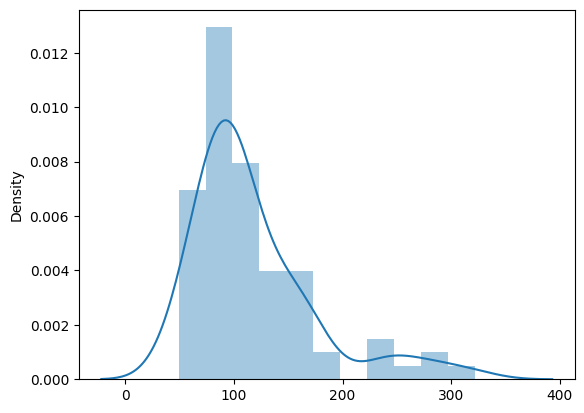

In [31]:
sb.distplot(x=car_data["HP"])   ## deprecated version

<Axes: ylabel='Density'>

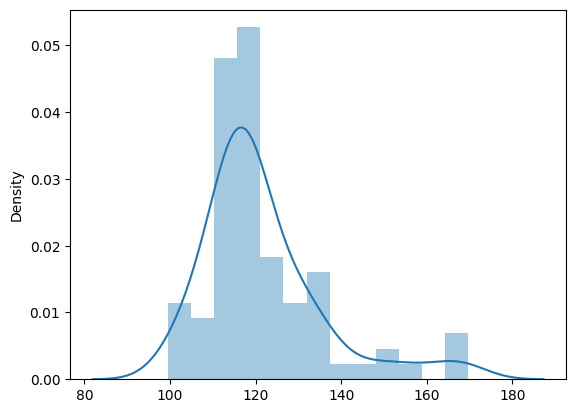

In [33]:
sb.distplot(x=car_data["SP"])

<Axes: ylabel='Density'>

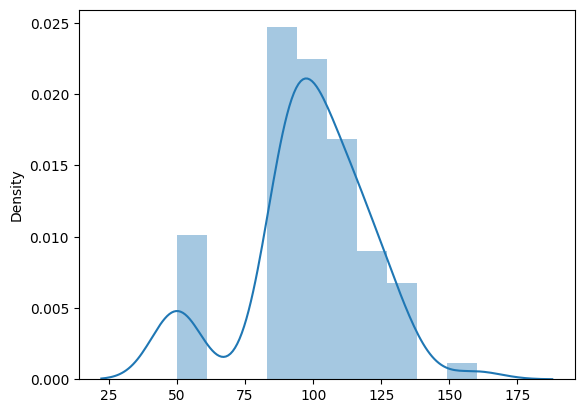

In [34]:
sb.distplot(x=car_data["VOL"])

<Axes: ylabel='Density'>

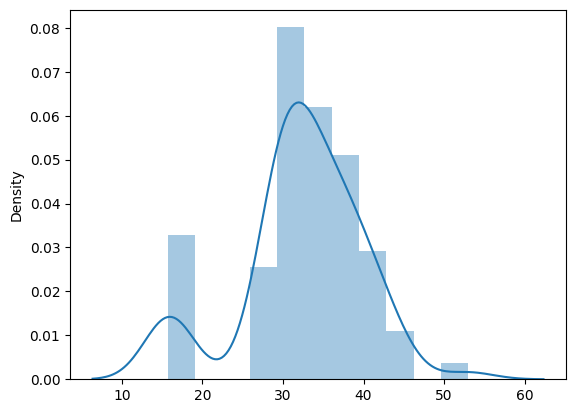

In [35]:
sb.distplot(x=car_data["WT"])

### Test 2 Normality Failed

## Test 3 Multicollineartiy Test

In [6]:
corr_matrix = car_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


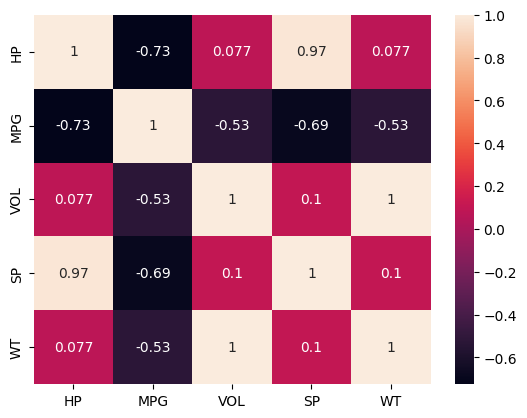

In [7]:
sb.heatmap(data=corr_matrix,annot=True)
pyt.show()

### Test 3 - There is Multicollineraity Data



### Test 4 - AutoRegression Passed

## 4.Data Preparation

In [56]:
car_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


In [8]:
x= car_data[["HP","VOL","SP","WT"]]
x

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [9]:
y=car_data["MPG"]
y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

### There is nothing to prepare because all feature are numeric

## 5.Model Building

In [10]:
linear_model = LinearRegression()

## 6.Model Traning 

In [11]:
linear_model.fit(x,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
linear_model.intercept_    ## intercept value

np.float64(30.67733585215171)

In [13]:
linear_model.coef_   ## each column have slope value

array([-0.20544372, -0.33605084,  0.39562692,  0.40057409])

## 7.Model Testing

In [14]:
y_predict = linear_model.predict(x)
y_predict

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

## 8.Model Evaluation

In [15]:
error = y - y_predict 
error

0     10.258747
1      7.624608
2      7.734060
3      3.157963
4      8.331584
        ...    
76    15.617904
77     1.298838
78     7.863547
79     7.517122
80    -3.458218
Name: MPG, Length: 81, dtype: float64

In [16]:
error.mean() 

np.float64(-4.495717926877177e-15)

In [17]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [18]:
mean_absolute_error(y,y_predict)    ## same units 

3.267968285420799

In [19]:
mean_squared_error(y,y_predict) ## square output units

18.897141152343107

In [20]:
root_mean_squared_error(y, y_predict)  ## normalise the unit 

4.347084212704316

In [21]:
r2_score(y,y_predict) 

0.7705372737359844

#### Adjust R2

In [34]:
import statsmodels.formula.api as smf

In [33]:
!python -m pip install statsmodels --timeout 600 --retries 10

     ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
     ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
     ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
     ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
     --------------------------------------- 0.0/11.4 MB 222.6 kB/s eta 0:00:51
     --------------------------------------- 0.0/11.4 MB 220.2 kB/s eta 0:00:52
     --------------------------------------- 0.1/11.4 MB 273.8 kB/s eta 0:00:42
     --------------------------------------- 0.1/11.4 MB 273.8 kB/s eta 0:00:42
     --------------------------------------- 0.1/11.4 MB 273.8 kB/s eta 0:00:42
     --------------------------------------- 0.1/11.4 MB 276.8 kB/s eta 0:00:41
     --------------------------------------- 0.1/11.4 MB 285.2 kB/s eta 0:00:40
     --------------------------------------- 0.1/11.4 MB 277.4 kB/s eta 0:00:41
     --------------------------------------- 0.1/11.4 MB 316.2 kB/s eta 


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
pip install --upgrade pip

     ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
      --------------------------------------- 0.0/1.8 MB 1.3 MB/s eta 0:00:02
      --------------------------------------- 0.0/1.8 MB 487.6 kB/s eta 0:00:04
      --------------------------------------- 0.0/1.8 MB 487.6 kB/s eta 0:00:04
     -- ------------------------------------- 0.1/1.8 MB 581.0 kB/s eta 0:00:03
     -- ------------------------------------- 0.1/1.8 MB 504.4 kB/s eta 0:00:04
     -- ------------------------------------- 0.1/1.8 MB 504.4 kB/s eta 0:00:04
     --- ------------------------------------ 0.2/1.8 MB 551.6 kB/s eta 0:00:03
     --- ------------------------------------ 0.2/1.8 MB 551.6 kB/s eta 0:00:03
     --- ------------------------------------ 0.2/1.8 MB 551.6 kB/s eta 0:00:03
     ----- ---------------------------------- 0.3/1.8 MB 542.5 kB/s eta 0:00:03
     ------ --------------------------------- 0.3/1.8 MB 570.1 kB/s eta 0:00:03
     ------ --------------------------------- 0.3/1

ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\Mathan\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "C:\Users\Mathan\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
  File "C:\Users\Mathan\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
  File "C:\Users\Mathan\AppData\Local\Programs\Python\Python310\lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 90, in read
    data = self.__fp.read(amt)
  File "C:\Users\Mathan\AppData\Local\Programs\Python\Python310\lib\http\client.py", line 466, in read
    s = self.fp.read(amt)
  File "C:\Users\Mathan\AppData\Local\Programs\Python\Python310\lib\socket.py", line 705, in r

### RO see Adjusted R2 Score, we are using OLS technique from Stats Model Formula

In [40]:
linear_stats_model= smf.ols(formula ='MPG ~ HP' ,data=car_data).fit()

In [42]:
car_data.head()

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149


In [41]:
print("R2 score :", linear_stats_model.rsquared,"\nAdjusted R2 Score:",linear_stats_model.rsquared_adj.round(4))

R2 score : 0.5256806086282022 
Adjusted R2 Score: 0.5197


In [43]:
linear_stats_model= smf.ols(formula ='MPG ~ HP+VOL' ,data=car_data).fit()

In [44]:
print("R2 score :", linear_stats_model.rsquared,"\nAdjusted R2 Score:",linear_stats_model.rsquared_adj.round(4))

R2 score : 0.7506606277376424 
Adjusted R2 Score: 0.7443


In [45]:
linear_stats_model= smf.ols(formula ='MPG ~ HP+VOL+SP' ,data=car_data).fit()
print("R2 score :", linear_stats_model.rsquared,"\nAdjusted R2 Score:",linear_stats_model.rsquared_adj.round(4))

R2 score : 0.770368341321302 
Adjusted R2 Score: 0.7614


In [46]:
linear_stats_model= smf.ols(formula ='MPG ~ HP+VOL+SP+WT' ,data=car_data).fit()
print("R2 score :", linear_stats_model.rsquared,"\nAdjusted R2 Score:",linear_stats_model.rsquared_adj.round(4))

R2 score : 0.7705372737359844 
Adjusted R2 Score: 0.7585


## Lets now perform Test 5: Homoscedasticity Test

<Axes: xlabel='HP', ylabel='MPG'>

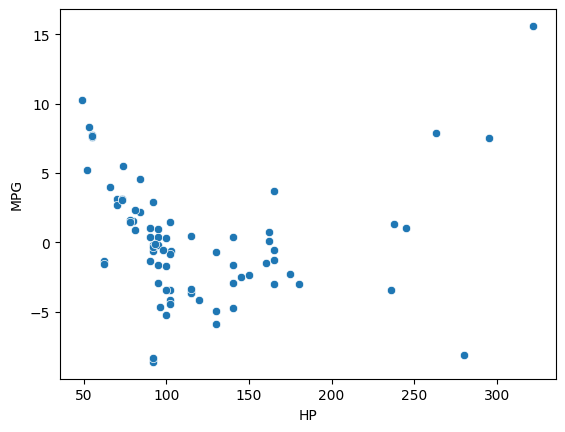

In [71]:
sb.scatterplot(data=car_data,x="HP",y=error)       #Failed

<Axes: xlabel='VOL', ylabel='MPG'>

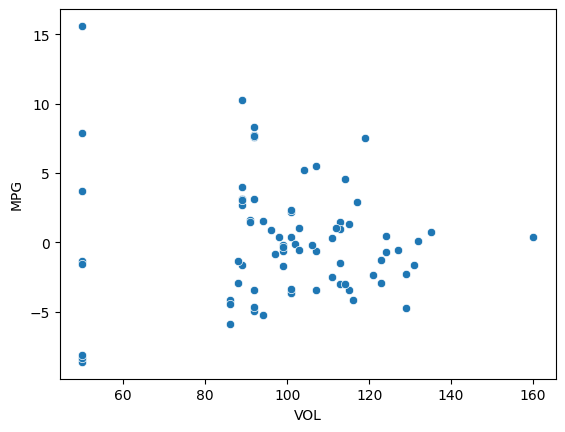

In [72]:
sb.scatterplot(data=car_data,x="VOL",y=error)   ## Failed

<Axes: xlabel='SP', ylabel='MPG'>

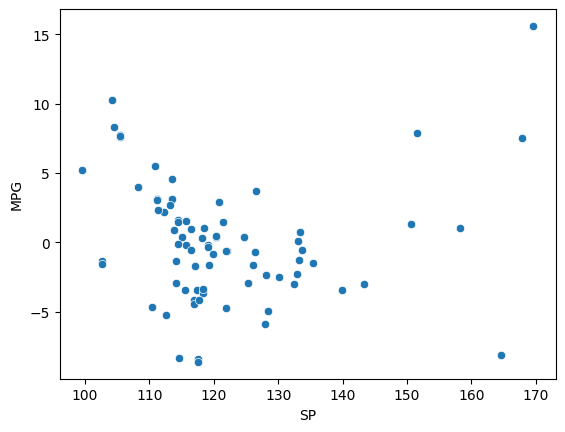

In [73]:
sb.scatterplot(data=car_data,x="SP",y=error)   ## Failed

<Axes: xlabel='WT', ylabel='MPG'>

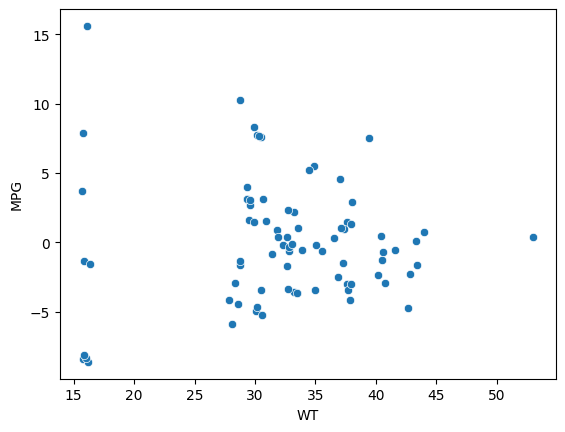

In [74]:
sb.scatterplot(data=car_data,x="WT",y=error)   ## Failed

#### Test 5 Homoscedasticity Test Failed

## Test 6 Zero Residial Mean

<Axes: xlabel='MPG'>

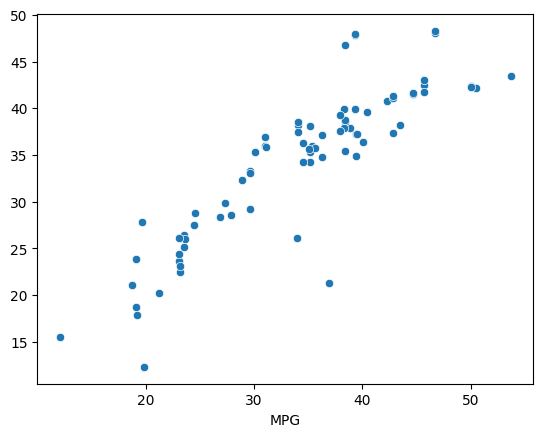

In [76]:
sb.scatterplot(x=car_data['MPG'],y=y_predict) 

#### Test 6 Zero Residual Mean Test is Failed

## 9.Model Deployment

In [80]:
from pickle import dump
dump(obj=linear_model,file=open(file="linear_intellegence_file.pkl" ,mode ="wb"))


#### Using Backend Pickle file 

In [82]:
from pickle import load

In [83]:
linear_intel_pkl = load(file=open(file="linear_intellegence_file.pkl" ,mode ="rb"))
linear_intel_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [84]:
linear_intel_pkl.predict(x)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

## The End

## Spreate Train and Test



## Model Build 

In [53]:
Linear_model=LinearRegression()

In [60]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_Test=train_test_split(x,y,test_size=0.20,shuffle=True,random_state=34)
print(X_train,X_test,y_train,y_Test)

     HP  VOL          SP         WT
17   92   50  117.598513  16.194122
52  115  124  120.404312  40.398164
16   78   91  114.369293  29.535784
39  130   92  128.461264  30.115434
22   95  101  120.288996  32.675828
..  ...  ...         ...        ...
11   92   50  117.598513  15.753535
69  245  112  158.300669  37.141733
35   90   98  115.013085  31.911223
68  165  123  133.312342  40.472042
33  102  113  121.392639  37.573290

[64 rows x 4 columns]      HP  VOL          SP         WT
59  100  115  115.576579  37.662874
49  115  101  118.288996  33.458472
7    62   50  102.598513  15.847758
27   92   99  119.105055  32.835069
74  140  129  121.864163  42.618698
61  120  116  117.668550  37.860411
64  150  121  128.128401  40.159482
12   92   99  122.105055  32.813592
44   93  102  114.380966  33.078632
30   84  114  113.484609  37.042350
0    49   89  104.185353  28.762059
15   73   89  111.185353  29.604527
3    70   92  113.461264  30.632114
48  130   86  127.909442  28.070597
78  2

## Model Training For Training

In [63]:
Linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## Model Testing For Training

In [68]:
y_train_predict=Linear_model.predict(X_train)
y_train_predict

array([46.75462614, 29.357921  , 40.59531094, 35.55326361, 37.45059013,
       41.68332337, 32.74736225, 38.35204467, 15.7960024 , 40.45702296,
       39.41888236, 37.47703884, 41.42599626, 23.56427857, 41.17403166,
       26.5237502 , 28.78854008, 35.36168615, 34.25957557, 45.49336752,
       28.4717663 , 35.06820535, 37.09928504, 35.15766796, 36.67235696,
       33.15321636, 42.01639762, 27.80720182, 39.307307  , 38.31289001,
       35.40477942, 23.98357674, 20.38133197, 35.57491245, 36.87008928,
       37.67749978, 41.91914635, 38.82344891, 41.18680984, 30.1294102 ,
       26.62411662, 12.83999048, 36.13102051, 37.3420992 , 35.52563974,
       47.2231036 , 34.40109066, 26.95474873, 37.18263291, 37.54744214,
       33.34178579, 22.83470605, 42.72264178, 25.77796412, 38.23393319,
       19.94553155, 21.76768197, 40.92851149, 36.08544444, 46.38165859,
       20.50748319, 37.20180937, 24.76848656, 35.04420344])

## Model Evaluation

In [71]:
error_train = y_train-y_train_predict
error_train

17   -7.400532
52    0.272015
16    2.194598
39   -4.539133
22    0.860016
        ...   
11   -7.027564
69    0.766225
35    0.756934
68   -1.665315
33    1.241253
Name: MPG, Length: 64, dtype: float64

In [72]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [74]:
mean_absolute_error(y_train,y_train_predict)

3.129830577722012

In [75]:
mean_squared_error(y_train,y_train_predict)

17.7676167791103

In [76]:
root_mean_squared_error(y_train,y_train_predict)

4.215165095119087

In [77]:
r2_score(y_train,y_train_predict)

0.7657768244482416

In [78]:
import statsmodels.formula.api as smf

In [79]:
car_data.head()

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149


In [81]:
linear_model_stats=smf.ols(formula='MPG ~ HP+VOL+SP+WT',data=car_data).fit()
linear_model_stats.predict(x
linear_model_stats.rsquared.round(3) 
linear_model_stats.rsquared_adj.round(3)